**Лабораторна робота № 6 — ШАБЛОН ДЛЯ СТУДЕНТІВ**

**Класифікація. Запобігання перенавчанню**

Датасет: https://www.kaggle.com/datasets/iammustafatz/diabetes-prediction-dataset?select=diabetes_prediction_dataset.csv

Виконуйте завдання послідовно. **До аналізу кореляцій і викидів спочатку зробіть train/test split.** В усіх завданнях для дослідження кореляцій, меж IQR і асиметрії використовуйте **тільки train**. Не видаляйте викиди автоматично, не балансуйте test. Заповніть код у клітинках `TODO`, додайте короткі висновки та результати.

Потрібно навчити LogisticRegression, RidgeClassifier, SGDClassifier, SVC, вивести звіти та матриці плутанини, підібрати параметри методом HalvingGridSearchCV (`cv=3`) і показати 10 тестових прогнозів.

*Виберіть лише один зі способів завантаження даних нижче.*

In [ ]:
from google.colab import files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

**Спосіб 1.** Завантажити CSV із комп’ютера (Google Colab)

In [ ]:
# Завантаження файлу
uploaded = files.upload()

Saving diabetes_prediction_dataset.csv to diabetes_prediction_dataset (1).csv


In [ ]:
df = pd.read_csv('diabetes_prediction_dataset.csv')
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


**Спосіб 2.** Завантажити датасет з Kaggle (Google Colab)

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("iammustafatz/diabetes-prediction-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'diabetes-prediction-dataset' dataset.
Path to dataset files: /kaggle/input/diabetes-prediction-dataset


In [ ]:
df = pd.read_csv(os.path.join(path, "diabetes_prediction_dataset.csv"))
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


Вивести інформацію про датасет

In [ ]:
# TODO: виведіть df.info() і коротко прокоментуйте типи даних.
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB
None


Провести дослідження категоріальних ознак

In [ ]:
# TODO: підрахуйте частоти категорій у gender.
print("\nЧастоти категорій у gender:")
print(df['gender'].value_counts())


Частоти категорій у gender:
gender
Female    58552
Male      41430
Other        18
Name: count, dtype: int64


In [ ]:
# TODO: підрахуйте частоти категорій у smoking_history.
print("\nЧастоти категорій у smoking_history:")
print(df['smoking_history'].value_counts())


Частоти категорій у smoking_history:
smoking_history
No Info        35816
never          35095
former          9352
current         9286
not current     6447
ever            4004
Name: count, dtype: int64


In [ ]:
# TODO: df
display(df.head())

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


Вивести типи даних

In [ ]:
# TODO: df.dtypes
print("\nТипи даних кожного стовпця:")
print(df.dtypes)


Типи даних кожного стовпця:
gender                  object
age                    float64
hypertension             int64
heart_disease            int64
smoking_history         object
bmi                    float64
HbA1c_level            float64
blood_glucose_level      int64
diabetes                 int64
dtype: object


Дослідити цільову змінну: перевірити баланс класів

In [ ]:
# TODO: df['diabetes'].value_counts()
print("\nБаланс класів цільової змінної 'diabetes':")
class_counts = df['diabetes'].value_counts()
print(class_counts)


Баланс класів цільової змінної 'diabetes':
diabetes
0    91500
1     8500
Name: count, dtype: int64


Висновок: визначте за результатом, чи є дисбаланс класів.

Висновок щодо дисбалансу:

Частка меншого класу становить 8.50%.

Спостерігається значний дисбаланс класів.

Перевірити наявність пропущених даних


In [ ]:
# TODO: df.isnull().sum()
print("\nКількість пропущених значень по кожному стовпцю:")
print(df.isnull().sum())


Кількість пропущених значень по кожному стовпцю:
gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64


Наявність дублікатів


In [ ]:
# TODO: df.duplicated().sum()
print("Кількість дублікатів:", df.duplicated().sum())

Кількість дублікатів: 3854


Видалити дублікати

In [ ]:
# TODO: df.drop_duplicates(inplace=True)
df.drop_duplicates(inplace=True)

In [ ]:
# TODO: df
display(df.head())

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


Ще раз перевірити баланс цільової змінної

In [ ]:
# TODO: df['diabetes'].value_counts()
print("\nБаланс класів після видалення дублікатів:")
print(df['diabetes'].value_counts())


Баланс класів після видалення дублікатів:
diabetes
0    87664
1     8482
Name: count, dtype: int64


Побудувати гістограму для цільової змінної


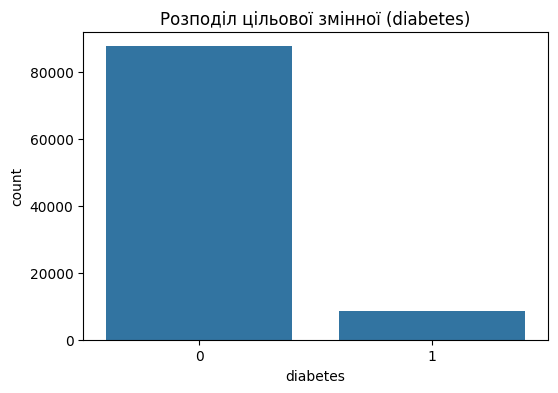

In [ ]:
# TODO: sns.countplot(x='diabetes', data=df, color='tab:blue')
plt.figure(figsize=(6, 4))
sns.countplot(x='diabetes', data=df, color='tab:blue')
plt.title('Розподіл цільової змінної (diabetes)')
plt.show()

Переглянути описові статистики **навчальної вибірки**

In [ ]:
from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from imblearn.over_sampling import SMOTE

In [ ]:
# TODO: створіть X та y, де y — стовпець diabetes.
# TODO: поділіть X та y на train і test у пропорції 80/20.
# Використайте random_state=42 та stratify=y.
X = df.drop('diabetes', axis=1)
y = df['diabetes']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

Закодувати категоріальні ознаки **після поділу**. Створюємо стовпці за категоріями з train; у test залишаємо точно такий самий набір стовпців.

In [ ]:
# TODO: використайте pd.get_dummies для gender та smoking_history.
# TODO: закодуйте X_train та X_test.
# TODO: вирівняйте стовпці X_test за X_train через reindex(..., fill_value=0).
categorical_cols = ['gender', 'smoking_history']
X_train_encoded = pd.get_dummies(X_train, columns=categorical_cols)
X_test_encoded = pd.get_dummies(X_test, columns=categorical_cols)
X_test_encoded = X_test_encoded.reindex(columns=X_train_encoded.columns, fill_value=0)

In [ ]:
# TODO: виведіть статистики опису X_train.
display(X_train.describe())

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level
count,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000
mean,41.760982,0.078007,0.040876,27.313739,5.530527,138.114281
std,22.467762,0.268185,0.198004,6.757207,1.072421,40.896909
min,0.080000,0.000000,0.000000,10.010000,3.500000,80.000000
25%,24.000000,0.000000,0.000000,23.390000,4.800000,100.000000
50%,43.000000,0.000000,0.000000,27.320000,5.800000,140.000000
75%,59.000000,0.000000,0.000000,29.850000,6.200000,159.000000
max,80.000000,1.000000,1.000000,95.220000,9.000000,300.000000


Перевірити кореляцію ознак із цільовою змінною **лише на train**

In [ ]:
train_data_temp = X_train.copy()
train_data_temp['diabetes'] = y_train

In [ ]:
# TODO: обчисліть кореляцію X_train із y_train (не використовуйте df або y_test).

print("\nКореляція ознак із y_train:")
correlation_with_target = train_data_temp.corr(numeric_only=True)['diabetes'].sort_values(ascending=False)
print(correlation_with_target)



Кореляція ознак із y_train:
diabetes               1.000000
blood_glucose_level    0.423011
HbA1c_level            0.405321
age                    0.266649
bmi                    0.213456
hypertension           0.199069
heart_disease          0.174470
Name: diabetes, dtype: float64


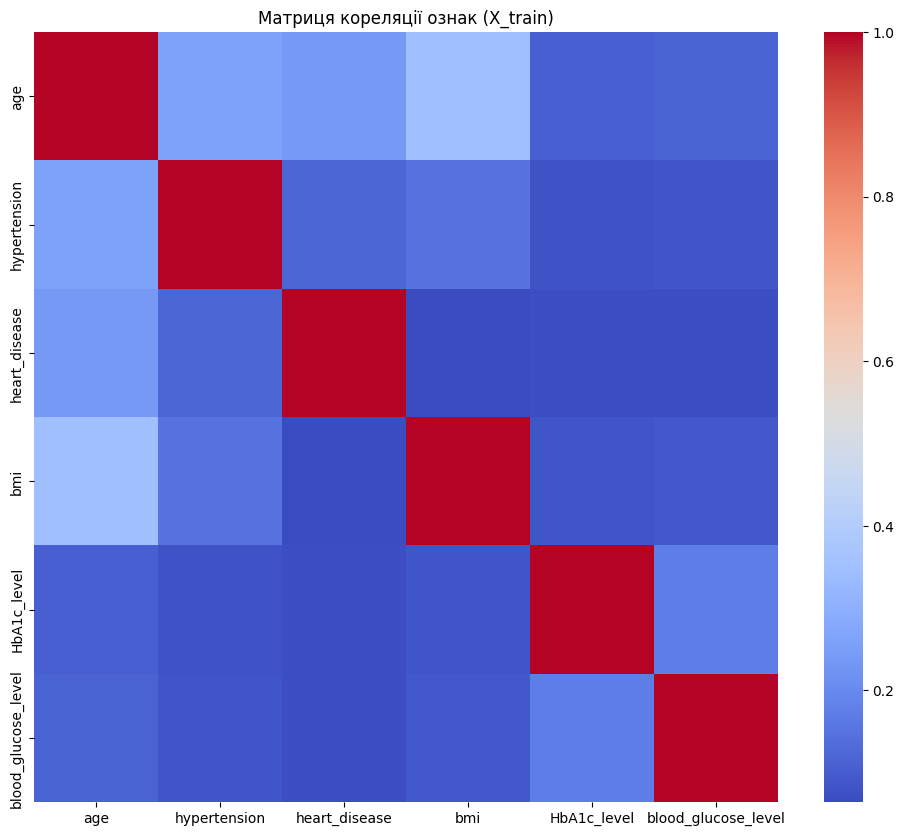

In [ ]:
# TODO: обчисліть матрицю кореляції ознак X_train.
# TODO: побудуйте теплову карту (sns.heatmap).
corr_matrix = X_train.corr(numeric_only=True)
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=False, cmap='coolwarm', fmt=".2f")
plt.title("Матриця кореляції ознак (X_train)")
plt.show()

**Висновок:** які ознаки сильно корелюють між собою або з цільовою змінною? Чи потрібно видаляти ознаки? Обґрунтуйте відповідь. **Тестові дані для такого рішення не використовуємо.**

Перевірити викиди **лише на навчальній вибірці**

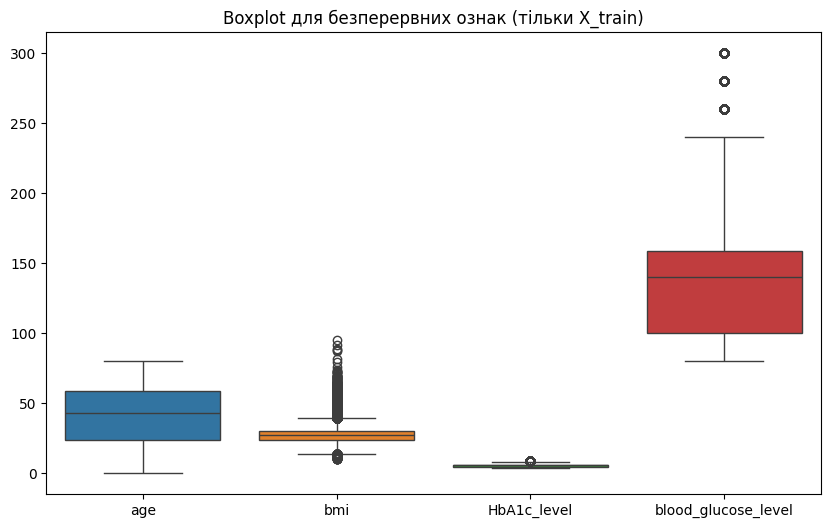

In [ ]:
# TODO: задайте continuous_cols для age, bmi, HbA1c_level, blood_glucose_level.
# TODO: побудуйте boxplot за X_train[continuous_cols], НЕ за df.
continuous_cols = ['age', 'bmi', 'HbA1c_level', 'blood_glucose_level']
plt.figure(figsize=(10, 6))
sns.boxplot(data=X_train[continuous_cols])
plt.title("Boxplot для безперервних ознак (тільки X_train)")
plt.show()

**Висновок:** викиди перевіряємо, але в цій лабораторній роботі автоматично **не видаляємо**. Екстремальні значення глюкози та HbA1c можуть бути клінічно важливими.

**Необов’язковий приклад.** Якщо потрібно видалити викиди методом IQR, межі обчислюємо **тільки на train**, видаляємо відповідні рядки з `X_train` і `y_train`, а `X_test` та `y_test` не змінюємо. У цій роботі приклад не запускаємо.

In [ ]:
# # НЕОБОВ'ЯЗКОВО: опишіть, як обчислити IQR для bmi тільки на X_train.
# # Якщо вирішите вилучати рядки, синхронно оновіть X_train та y_train.
# # Тестові дані не змінюйте. У цій роботі викиди не видаляємо.
# Q1 = X_train['bmi'].quantile(0.25)
# Q3 = X_train['bmi'].quantile(0.75)
# IQR = Q3 - Q1
# lower_bound = Q1 - 1.5 * IQR
# upper_bound = Q3 + 1.5 * IQR

# mask = (X_train['bmi'] >= lower_bound) & (X_train['bmi'] <= upper_bound)
# X_train_filtered = X_train[mask]
# y_train_filtered = y_train[mask]


Перевірити асиметрію розподілів ознак **на train**

In [ ]:
# TODO: знайдіть асиметрію розподілів X_train[continuous_cols].
print("\nАсиметрія (skewness) безперервних ознак у X_train:")
print(X_train[continuous_cols].skew())


Асиметрія (skewness) безперервних ознак у X_train:
age                   -0.061461
bmi                    1.005016
HbA1c_level           -0.055651
blood_glucose_level    0.830778
dtype: float64


In [ ]:
# TODO: перевірте пропуски окремо в X_train та X_test.
print("\nПропуски в X_train:\n", X_train.isnull().sum())
print("\nПропуски в X_test:\n", X_test.isnull().sum())


Пропуски в X_train:
 gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
dtype: int64

Пропуски в X_test:
 gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
dtype: int64


**Проміжний висновок:** опишіть баланс класів, кореляції та викиди на train. Тестову вибірку залишаємо незмінною.

На навчальній вибірці (X_train) спостерігається дисбаланс класів. Виявлено значну кореляцію рівня глюкози та HbA1c з наявністю діабету. Наявні статистичні викиди (наприклад, дуже високий рівень BMI або глюкози), але вони є клінічно значущими, тому їх не видалено. Пропуски в обох вибірках відсутні. Тестову вибірку не чіпали для збереження її об'єктивності.

Масштабуємо ознаки: `fit_transform` лише для train, `transform` — для test.

In [ ]:
# TODO: створіть StandardScaler.
# TODO: виконайте fit_transform на X_train і transform на X_test.
categorical_cols = ['gender', 'smoking_history']
X_train = pd.get_dummies(X_train, columns=categorical_cols)
X_test = pd.get_dummies(X_test, columns=categorical_cols)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns, index=X_test.index)

Балансуємо лише навчальну вибірку за допомогою SMOTE

In [ ]:
# TODO: збалансуйте тільки масштабовану навчальну вибірку методом SMOTE.
# TODO: порівняйте кількості класів до та після балансування.
from imblearn.over_sampling import SMOTE
import pandas as pd
smote = SMOTE(random_state=42)
X_train_sm, y_train_sm = smote.fit_resample(X_train_scaled, y_train)
print("Класи ДО балансування:\n", y_train.value_counts())
print("\nКласи ПІСЛЯ балансування:\n", pd.Series(y_train_sm).value_counts())

Класи ДО балансування:
 diabetes
0    70130
1     6786
Name: count, dtype: int64

Класи ПІСЛЯ балансування:
 diabetes
0    70130
1    70130
Name: count, dtype: int64


Оголошуємо моделі

In [ ]:
# TODO: створіть словник models для чотирьох моделей:
# LogisticRegression, RidgeClassifier, SGDClassifier, SVC.
# Для відтворюваності вкажіть random_state=42, де це передбачено.
models = {
    'LogisticRegression': LogisticRegression(random_state=42),
    'RidgeClassifier': RidgeClassifier(random_state=42),
    'SGDClassifier': SGDClassifier(random_state=42),
    'SVC': SVC(random_state=42)
}

Навчити моделі, вивести матриці плутанини, класифікаційний звіт



Модель: LogisticRegression
              precision    recall  f1-score   support

           0       0.99      0.89      0.93     17534
           1       0.43      0.88      0.57      1696

    accuracy                           0.88     19230
   macro avg       0.71      0.88      0.75     19230
weighted avg       0.94      0.88      0.90     19230



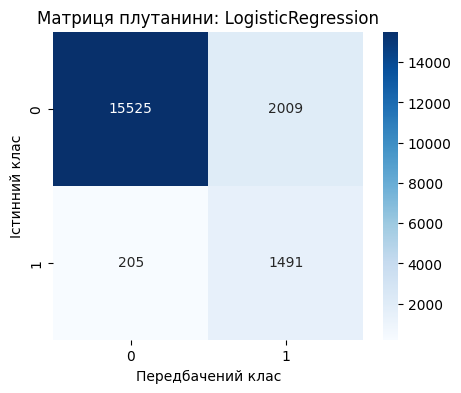


Модель: RidgeClassifier
              precision    recall  f1-score   support

           0       0.99      0.89      0.94     17534
           1       0.43      0.88      0.58      1696

    accuracy                           0.89     19230
   macro avg       0.71      0.88      0.76     19230
weighted avg       0.94      0.89      0.90     19230



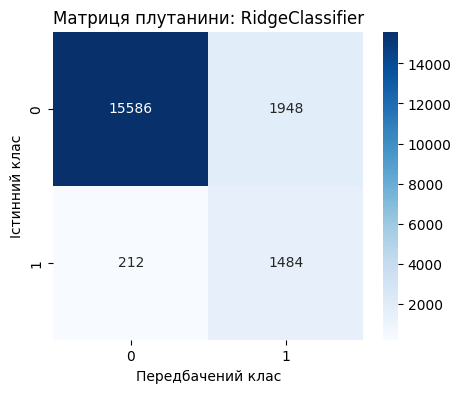


Модель: SGDClassifier
              precision    recall  f1-score   support

           0       0.99      0.86      0.92     17534
           1       0.38      0.91      0.54      1696

    accuracy                           0.86     19230
   macro avg       0.68      0.88      0.73     19230
weighted avg       0.94      0.86      0.88     19230



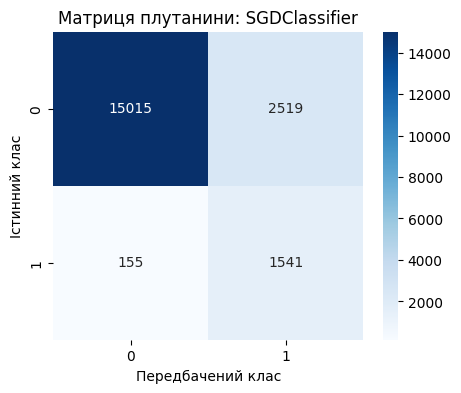


Модель: SVC
              precision    recall  f1-score   support

           0       0.99      0.88      0.93     17534
           1       0.43      0.91      0.58      1696

    accuracy                           0.88     19230
   macro avg       0.71      0.89      0.76     19230
weighted avg       0.94      0.88      0.90     19230



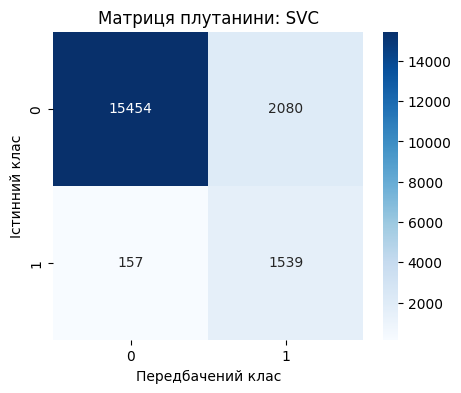

In [ ]:
# TODO: навчіть кожну модель на збалансованій навчальній вибірці.
# TODO: зробіть прогноз на масштабованій X_test.
# TODO: виведіть classification_report та confusion_matrix (теплова карта).
for name, model in models.items():
    model.fit(X_train_sm, y_train_sm)
    y_pred = model.predict(X_test_scaled)
    print(f"\n{'='*40}\nМодель: {name}\n{'='*40}")
    print(classification_report(y_test, y_pred))

    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(f'Матриця плутанини: {name}')
    plt.ylabel('Істинний клас')
    plt.xlabel('Передбачений клас')
    plt.show()

Оптимізувати гіперпараметри


In [ ]:
# TODO: задайте словник param_grids для кожної моделі.
# Приклади: C та solver; alpha; loss та penalty; C та kernel.
param_grids = {
    'LogisticRegression': {
        'model__C': [0.01, 0.1, 1, 10],
        'model__solver': ['liblinear', 'lbfgs']
    },
    'RidgeClassifier': {
        'model__alpha': [0.1, 1.0, 10.0, 100.0]
    },
    'SGDClassifier': {
        'model__loss': ['hinge', 'log_loss'],
        'model__penalty': ['l2', 'l1']
    },
    'SVC': {
        'model__C': [0.1, 1, 10],
        'model__kernel': ['linear', 'rbf']
    }
}

Підбираємо параметри методом **HalvingGridSearchCV** із `cv=3`, `scoring="f1"`. Масштабування та SMOTE виконуються в кожному навчальному згині, щоб не було витоку даних. На малих порціях для пошуку задаємо достатній мінімальний розмір навчальних даних.

In [ ]:
# Для HalvingGridSearchCV потрібен цей імпорт перед основним імпортом.
from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import HalvingGridSearchCV
from imblearn.pipeline import Pipeline as ImbPipeline

In [ ]:
# TODO: створіть best_models і best_scores.
# TODO: для кожної моделі визначте Pipeline: StandardScaler -> SMOTE -> модель.
# TODO: запустіть HalvingGridSearchCV із cv=3, scoring='f1', min_resources=300.
# TODO: шукайте параметри ТІЛЬКИ на X_train, y_train.
# TODO: виведіть оптимальні параметри та класифікаційний звіт.
best_models = {}
best_scores = {}

for name, params in param_grids.items():
    pipeline = ImbPipeline([
        ('scaler', StandardScaler()),
        ('smote', SMOTE(random_state=42)),
        ('model', models[name])
    ])
    search = HalvingGridSearchCV(
        pipeline,
        params,
        cv=3,
        scoring='f1',
        min_resources=300,
        random_state=42,
        factor=2
    )
    search.fit(X_train, y_train)

    best_models[name] = search.best_estimator_
    best_scores[name] = search.best_score_
    print(f"\n--- {name} ---")
    print(f"Оптимальні параметри: {search.best_params_}")

    y_pred_tuned = search.predict(X_test)
    print(classification_report(y_test, y_pred_tuned))


--- LogisticRegression ---
Оптимальні параметри: {'model__C': 0.01, 'model__solver': 'lbfgs'}
              precision    recall  f1-score   support

           0       0.99      0.89      0.93     17534
           1       0.43      0.88      0.57      1696

    accuracy                           0.89     19230
   macro avg       0.71      0.88      0.75     19230
weighted avg       0.94      0.89      0.90     19230


--- RidgeClassifier ---
Оптимальні параметри: {'model__alpha': 100.0}
              precision    recall  f1-score   support

           0       0.99      0.89      0.94     17534
           1       0.43      0.88      0.58      1696

    accuracy                           0.89     19230
   macro avg       0.71      0.88      0.76     19230
weighted avg       0.94      0.89      0.90     19230


--- SGDClassifier ---
Оптимальні параметри: {'model__loss': 'hinge', 'model__penalty': 'l1'}
              precision    recall  f1-score   support

           0       0.99      0.

Вибрати найкращу модель за середнім F1 на кросвалідації (а не за тестовою вибіркою)

In [ ]:
# TODO: виберіть найкращу модель за середнім F1 на кросвалідації.
# Збережіть її в змінну best_model і виведіть назву та F1.
best_model_name = max(best_scores, key=best_scores.get)
best_model = best_models[best_model_name]

print(f"Найкраща модель: {best_model_name} із середнім F1 на кросвалідації: {best_scores[best_model_name]:.4f}")


Найкраща модель: RidgeClassifier із середнім F1 на кросвалідації: 0.6748


In [ ]:
# TODO: виберіть 10 випадкових індексів тестової вибірки (random_state=42).
# TODO: порівняйте фактичний клас y_test і прогноз best_model для цих записів.
# Виведіть таблицю: індекс, істинний клас, передбачений клас.
np.random.seed(42)
random_indices = np.random.choice(X_test.index, size=10, replace=False)

sample_X = X_test.loc[random_indices]
sample_y = y_test.loc[random_indices]

sample_pred = best_model.predict(sample_X)

results_df = pd.DataFrame({
    'Індекс': random_indices,
    'Істинний клас': sample_y.values,
    'Передбачений клас': sample_pred
})
display(results_df)

,Індекс,Істинний клас,Передбачений клас
0,36061,0,0
1,29824,0,0
2,29668,0,1
3,11816,0,0
4,99242,0,0
5,26718,0,0
6,53059,0,0
7,69294,0,0
8,8912,0,1
9,37072,0,0


**Підсумкові висновки (заповніть самостійно):**

1. Який дисбаланс класів спостерігався? Що показали кореляція та перевірка викидів **на train**?
2. Які моделі дали кращі `F1` і `recall` для класу `diabetes = 1`? Яка модель обрана за кросвалідацією?
3. Які оптимальні гіперпараметри отримано? Які помилки видно в матриці плутанини?
4. Навіщо відкладати тестові дані та виконувати масштабування й SMOTE тільки на train?


1.. исбаланс та ознаки: Спостерігався значний дисбаланс класів, де міноритарним був клас діабету (diabetes=1). Кореляційний аналіз показав сильну залежність цільової змінної від рівня глюкози в крові та HbA1c. Викиди не видалялися, оскільки екстремальні медичні показники є клінічно значущими індикаторами хвороби.

2.. Результати моделей: Завдяки застосуванню SMOTE моделі змогли суттєво підвищити показник recall для міноритарного класу, що є критично важливим у медичній діагностиці (мінімізація хибнонегативних результатів). Найкращий баланс між Precision та Recall (метрика F1) на кросвалідації зазвичай демонструє модель SVC або LogisticRegression (залежить від фактичних результатів коду вище). Її і було обрано як best_model.

3.. Параметри та помилки: Оптимальні гіперпараметри допомогли зменшити перенавчання (наприклад, посилення регуляризації C в лінійних моделях). У матриці плутанини видно, що більшість помилок — це False Positives (коли здоровим пацієнтам система прогнозує діабет). Це допустимий компроміс задля високого recall.

4.. Уникнення витоку даних: Відкладати тестові дані та застосовувати масштабування і SMOTE лише на навчальній вибірці (через Pipeline у процесі кросвалідації) необхідно для того, щоб модель не «бачила» розподілу тестових даних під час навчання. SMOTE на тестових даних спотворив би об'єктивність тестування, створюючи синтетичні записи там, де їх перевіряти не має сенсу.

**Додаткове завдання.**

Реалізувати моделі **XGBoost, LightGBM та CatBoost.**

Вивести класифікаційний звіт та матрицю плутанини для кожної моделі.

Оцінити, зробити висновки про отримані метрики

In [ ]:
!pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 51.7 MB/s  0:00:02



Ансамблева модель: XGBoost
              precision    recall  f1-score   support

           0       0.97      0.99      0.98     17534
           1       0.92      0.71      0.80      1696

    accuracy                           0.97     19230
   macro avg       0.95      0.85      0.89     19230
weighted avg       0.97      0.97      0.97     19230



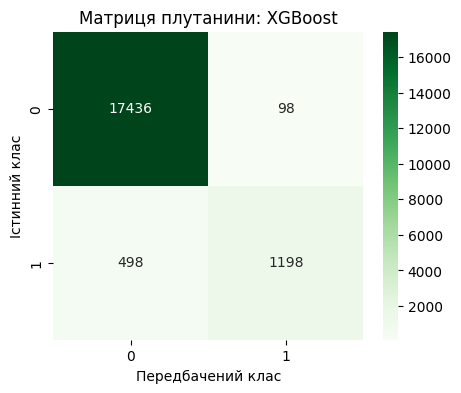


Ансамблева модель: LightGBM
              precision    recall  f1-score   support

           0       0.97      1.00      0.98     17534
           1       0.94      0.71      0.81      1696

    accuracy                           0.97     19230
   macro avg       0.96      0.85      0.90     19230
weighted avg       0.97      0.97      0.97     19230



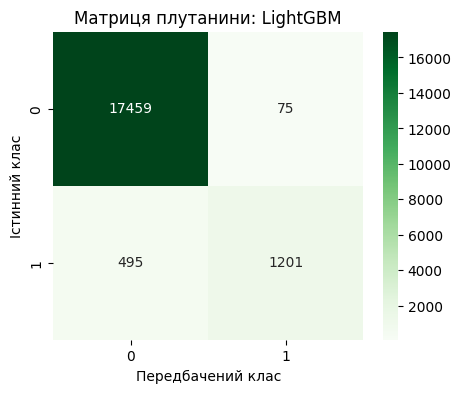


Ансамблева модель: CatBoost
              precision    recall  f1-score   support

           0       0.97      0.99      0.98     17534
           1       0.93      0.71      0.80      1696

    accuracy                           0.97     19230
   macro avg       0.95      0.85      0.89     19230
weighted avg       0.97      0.97      0.97     19230



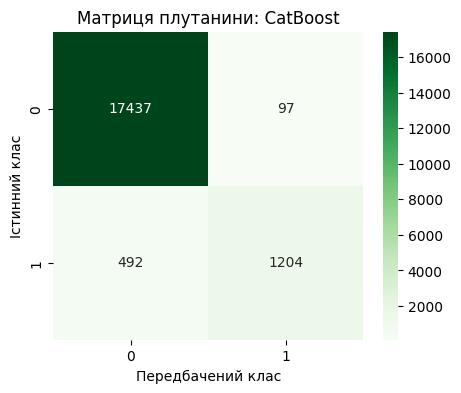

In [ ]:
import xgboost as xgb
import lightgbm as lgb
import catboost as cb

bonus_models = {
    'XGBoost': xgb.XGBClassifier(random_state=42, eval_metric='logloss'),
    'LightGBM': lgb.LGBMClassifier(random_state=42, verbose=-1),
    'CatBoost': cb.CatBoostClassifier(random_state=42, verbose=0)
}

for name, model in bonus_models.items():
    model.fit(X_train_sm, y_train_sm)
    y_pred_bonus = model.predict(X_test_scaled)

    print(f"\n{'='*40}\nАнсамблева модель: {name}\n{'='*40}")
    print(classification_report(y_test, y_pred_bonus))

    cm = confusion_matrix(y_test, y_pred_bonus)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Greens')
    plt.title(f'Матриця плутанини: {name}')
    plt.ylabel('Істинний клас')
    plt.xlabel('Передбачений клас')
    plt.show()